# Session 1 - A first model, and the baseline it has to beat

**Solutions.** Worked code and the numbers you should expect.

## What you will do today

You will build a model that predicts how toxic a small molecule is to a fish,
from numbers computed from its chemical structure alone. This is a *QSAR* model
(quantitative structure-activity relationship), and it is the kind of model that
regulators such as ECHA accept, under REACH, as partial evidence in place of an
animal test. So the question "how well does it really work?" is not academic.

Over the four sessions the modelling gets barely more sophisticated than
today's. What changes is how carefully we measure. By the end you should be
unable to look at a reported R<sup>2</sup> without asking three questions:
compared to what, averaged over what, and on which molecules.

**This session (2 h)**

1. Understand the data and the target, in units a toxicologist would recognise
2. Establish the baseline that any model must beat
3. Fit the first model, and see why a single train/test split is not an answer
4. Replace it with cross-validation and get the first number worth quoting

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so that `import qsar_helpers` works
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qsar_helpers import (load_fish, load_aquatic, xy, fold_error,
                          molecule_groups, score_table,
                          DESCRIPTOR_NOTES, TARGET_LABEL)

RNG = 0                            # one seed for the whole notebook
plt.rcParams.update({"figure.figsize": (6, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("pandas", pd.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

pandas 3.0.6
scikit-learn 1.9.1


## 1. The data

`qsar_fish_toxicity.csv`: 908 molecules, six molecular descriptors, and the
measured 96-hour LC50 toward *Pimephales promelas* (the fathead minnow) —
the concentration that kills half the exposed fish.

The target is reported as **-log10(mol/L)**. Watch the sign: a *high* value
means a *low* lethal concentration, i.e. a **more toxic** molecule. One unit on
this scale is a factor of ten in concentration.

In [2]:
fish = load_fish()
X, y = xy(fish)
print(fish.shape)
fish.head()

(908, 7)


    CIC0  SM1_Dz(Z)  GATS1i  NdsCH  NdssC  MLOGP   LC50
0  3.260      0.829   1.676      0      1  1.453  3.770
1  2.189      0.580   0.863      0      0  1.348  3.115
2  2.125      0.638   0.831      0      0  1.348  3.531
3  3.027      0.331   1.472      1      0  1.807  3.510
4  2.094      0.827   0.860      0      0  1.886  5.390

In [3]:
for name in X.columns:
    print(f"{name:>10s}  {DESCRIPTOR_NOTES[name]}")

      CIC0  complementary information content, order 0 (molecular complexity / symmetry)
 SM1_Dz(Z)  spectral moment from the Barysz matrix weighted by atomic number
    GATS1i  Geary autocorrelation, lag 1, weighted by ionisation potential
     NdsCH  count of =CH- fragments
     NdssC  count of =C< fragments
     MLOGP  Moriguchi octanol-water partition coefficient (lipophilicity)


Three of these describe the molecule's shape and electron distribution
(`CIC0`, `SM1_Dz(Z)`, `GATS1i`), two are counts of specific carbon fragments
(`NdsCH`, `NdssC`), and `MLOGP` is lipophilicity — how strongly the compound
prefers octanol over water.

### EXERCISE 1.1 — look at the target before you model it

Plot the distribution of `LC50` and report its mean, standard deviation, min
and max. Then answer in a sentence: across this dataset, what is the ratio
between the lethal concentration of the most and the least toxic molecule?

mean 4.064   sd 1.455   min 0.053   max 9.612
range = 9.56 log units  ->  a factor of 3,622,429,984 in concentration


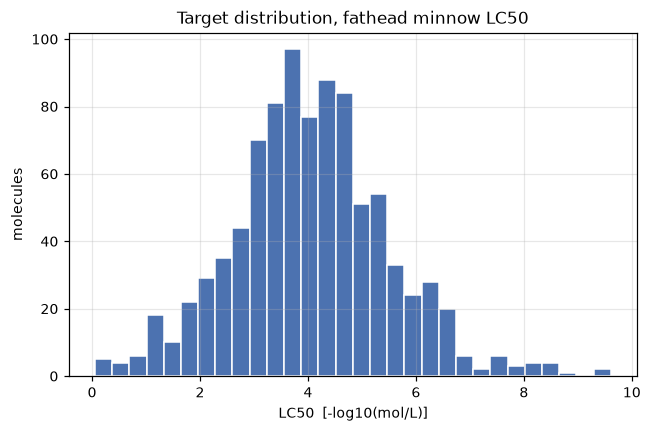

In [4]:
fig, ax = plt.subplots()
ax.hist(y, bins=30, color="#4C72B0", edgecolor="white")
ax.set_xlabel(TARGET_LABEL); ax.set_ylabel("molecules")
ax.set_title("Target distribution, fathead minnow LC50")
fig.tight_layout()

print(f"mean {y.mean():.3f}   sd {y.std():.3f}   min {y.min():.3f}   max {y.max():.3f}")
span = y.max() - y.min()
print(f"range = {span:.2f} log units  ->  a factor of {fold_error(span):,.0f} in concentration")

The target is close to symmetric (skew 0.25) and spans about 9.6 log units:
the least toxic compound needs roughly four billion times the concentration of
the most toxic one. That spread is why R<sup>2</sup> on this dataset can look
flattering — there is a lot of variance available to explain.

### EXERCISE 1.2 — which descriptors carry signal?

Make one scatter plot per descriptor against `LC50`, and compute the Pearson
correlation of each descriptor with the target. Which descriptor is the
strongest single predictor?

MLOGP        0.652
SM1_Dz(Z)    0.411
GATS1i      -0.398
CIC0         0.292
NdssC        0.172
NdsCH        0.172


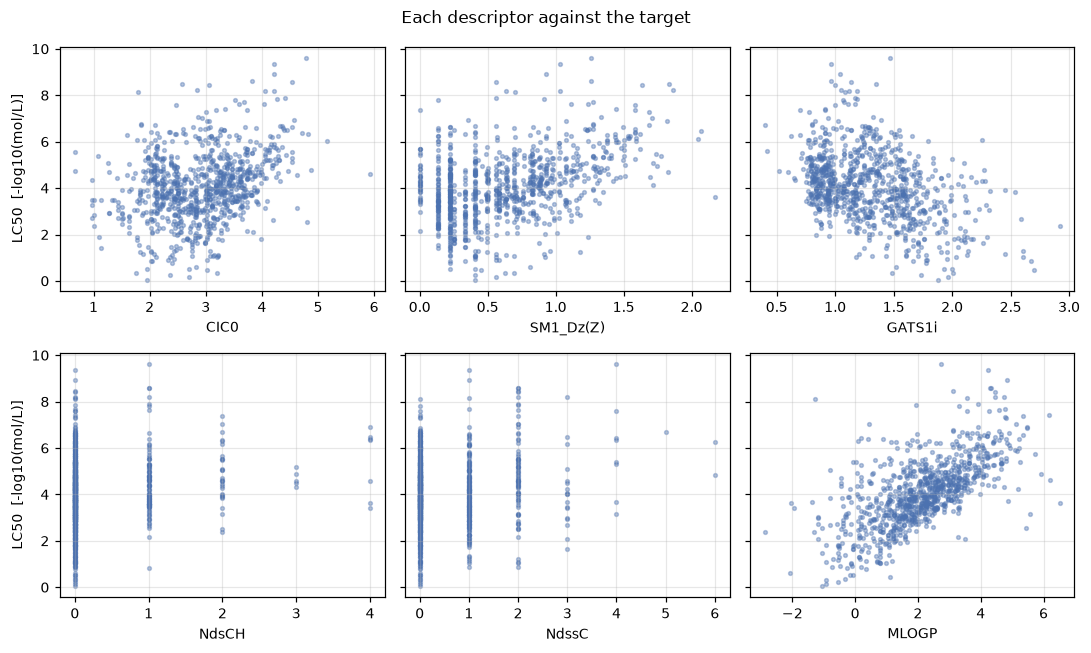

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharey=True)
for ax, name in zip(axes.ravel(), X.columns):
    ax.scatter(X[name], y, s=6, alpha=0.4, color="#4C72B0")
    ax.set_xlabel(name)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET_LABEL)
fig.suptitle("Each descriptor against the target")
fig.tight_layout()

corr = fish.corr(numeric_only=True)["LC50"].drop("LC50")
print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(3).to_string())

`MLOGP` leads with r = 0.65. That is not a coincidence of this dataset: for most
industrial organic chemicals, acute fish toxicity is dominated by **non-polar
narcosis** — the compound partitions into cell membranes and disrupts them, and
how much partitions in is largely a function of lipophilicity. A one-descriptor
model built on log P is the classical "baseline toxicity" line in
ecotoxicology, and it is the thing our six-descriptor model has to improve on.

Keep this in mind for session 4: a model whose predictions are driven by log P
is behaving the way the chemistry says it should. A model whose predictions are
driven by `NdssC` would need an explanation.

## 2. The baseline comes first

Before fitting anything, decide what "doing nothing" scores. The dumbest
possible predictor ignores the molecule and always predicts the mean LC50 of
the training set.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

cv5 = KFold(n_splits=5, shuffle=True, random_state=RNG)
dummy = cross_validate(DummyRegressor(strategy="mean"), X, y, cv=cv5,
                       scoring=("r2", "neg_root_mean_squared_error"))
print(f"dummy  R2   = {dummy['test_r2'].mean():+.3f}")
print(f"dummy  RMSE = {-dummy['test_neg_root_mean_squared_error'].mean():.3f} log units")

dummy  R2   = -0.016
dummy  RMSE = 1.456 log units


### EXERCISE 1.3 — two things to explain

1. The dummy's R<sup>2</sup> comes out slightly **negative**, -0.016.
   R<sup>2</sup> is often described as "the fraction of variance explained",
   which cannot be negative. Why is it negative here?
2. Its RMSE is about 1.45 log units. What does that mean as a fold-error in
   concentration? Use `fold_error`.

*Hint for (1): which mean is used for the prediction, and which mean does the
R<sup>2</sup> formula compare against, when the score is computed on a held-out
fold?*

In [7]:
rmse_dummy = -dummy["test_neg_root_mean_squared_error"].mean()
print(f"dummy RMSE {rmse_dummy:.3f} log units -> wrong by a factor of {fold_error(rmse_dummy):.0f}")

# (1) R2 on a held-out fold is 1 - SSE/SST where SST uses the *test* fold's own
#     mean, while the prediction is the *training* fold's mean. Those two means
#     differ by sampling noise, so the dummy is always very slightly worse than
#     the best possible constant for that fold, and R2 lands just below zero.
#     R2 = 0 is therefore the score of an *oracle* constant predictor; a
#     legitimately fitted dummy scores marginally less.

dummy RMSE 1.456 log units -> wrong by a factor of 29


A factor of 29 in concentration, which is useless — as it should be. Every
R<sup>2</sup> you report from now on is a claim about distance from this line.

## 3. One model, two scores, and a trap

Now fit an actual model. Split the data 75/25, fit a linear regression on the
training part, and score it on both parts.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, root_mean_squared_error

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)

print(f"train R2 = {r2_score(y_tr, lin.predict(X_tr)):.3f}")
print(f" test R2 = {r2_score(y_te, lin.predict(X_te)):.3f}")

train R2 = 0.577
 test R2 = 0.569


### EXERCISE 1.4 — the number that is not an estimate

Re-run the split-fit-score sequence for `random_state` = 0, 1, 2, ..., 9.
Collect the ten test-set R<sup>2</sup> values. Report the smallest and the
largest.

Then answer: if a colleague shows you a single test-set R<sup>2</sup> for a
model trained on 908 molecules, what have they actually told you?

In [9]:
scores = []
for seed in range(10):
    a, b, c, d = train_test_split(X, y, test_size=0.25, random_state=seed)
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(a, c)
    scores.append(r2_score(d, m.predict(b)))
scores = np.array(scores)
print(np.round(scores, 3))
print(f"min {scores.min():.3f}   max {scores.max():.3f}   "
      f"spread {np.ptp(scores):.3f}")

# They have told you the score of one model on one arbitrary quarter of the
# data. The spread across seeds here is of the same order as the difference
# between competing model families (session 3), so a single split cannot
# distinguish "better model" from "luckier split".

[0.442 0.487 0.573 0.585 0.618 0.596 0.575 0.587 0.611 0.538]
min 0.442   max 0.618   spread 0.176


Across ten seeds the test R<sup>2</sup> runs from 0.442 to 0.618 — a range of
0.18, for the *same model on the same data*. Session 2 is about that spread.

## 4. Cross-validation: the first number worth quoting

Instead of one split, use five, so that every molecule is predicted exactly once
by a model that never saw it.

In [10]:
lin_cv = cross_validate(make_pipeline(StandardScaler(), LinearRegression()),
                        X, y, cv=cv5,
                        scoring=("r2", "neg_root_mean_squared_error"))
r2 = lin_cv["test_r2"]
rmse = -lin_cv["test_neg_root_mean_squared_error"]
print(f"linear   R2   = {r2.mean():.3f} +- {r2.std():.3f}  (sd across 5 folds)")
print(f"linear   RMSE = {rmse.mean():.3f} log units -> factor {fold_error(rmse.mean()):.1f}")
print(f"per-fold R2: {np.round(r2, 3)}")

linear   R2   = 0.557 +- 0.043  (sd across 5 folds)
linear   RMSE = 0.960 log units -> factor 9.1
per-fold R2: [0.579 0.49  0.621 0.539 0.555]


### EXERCISE 1.5 — is this model fit for purpose?

The model is clearly far better than the dummy. But "better than nothing" is not
the standard a regulatory dossier is held to.

1. Convert the cross-validated RMSE into a fold-error in concentration.
2. Suppose a screening decision needs the predicted LC50 to be right within a
   factor of 3. What RMSE in log units does that correspond to? Does this model
   meet it?
3. Fit a model using `MLOGP` **alone** and cross-validate it. How much of the
   six-descriptor model's performance is just lipophilicity?

In [11]:
print(f"(1) RMSE {rmse.mean():.3f} log units -> factor {fold_error(rmse.mean()):.1f}")
print(f"(2) a factor-of-3 tolerance is log10(3) = {np.log10(3):.3f} log units;"
      f" this model is {rmse.mean()/np.log10(3):.1f}x worse than that")

from sklearn.model_selection import cross_val_score
only = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                       X[["MLOGP"]], y, cv=cv5, scoring="r2")
print(f"(3) MLOGP alone: R2 = {only.mean():.3f}   "
      f"all six: R2 = {r2.mean():.3f}")

(1) RMSE 0.960 log units -> factor 9.1
(2) a factor-of-3 tolerance is log10(3) = 0.477 log units; this model is 2.0x worse than that
(3) MLOGP alone: R2 = 0.408   all six: R2 = 0.557


## Where we are

| predictor | CV R<sup>2</sup> | CV RMSE (log units) | fold-error |
|---|---|---|---|
| mean of the training set | -0.016 | 1.456 | 29x |
| `MLOGP` alone | 0.408 | | |
| all six descriptors, linear | 0.557 ± 0.043 | 0.960 | 9.1x |

Three things to carry into session 2.

- A score is meaningless without the baseline next to it.
- A score from one train/test split moved over a range of 0.18 in
  R<sup>2</sup> across ten seeds, for reasons that have nothing to do with the
  model.
- Our best model so far is wrong by a factor of nine in concentration. Keep
  that in view when the R<sup>2</sup> starts climbing.